# EstiMate: Philippine Property Price Prediction

**Goal.** Build a regression model that estimates the asking price (PHP) of a Philippine home, and serve it in a Flask web app.

**Dataset.** `PH_houses_v2.csv` holds 1,500 real property listings. The `Link` column points each record to its Lamudi Philippines listing page; none of the data is synthetic. We chose it because it is Philippine-based, exceeds the 1,000-instance requirement, and contains the property details a home owner can actually provide.

**Columns.** `Description`, `Location`, `Price (PHP)` (target), `Bedrooms`, `Bath`, `Floor_area (sqm)`, `Land_area (sqm)`, `Latitude`, `Longitude`, `Link`.

**Limits of the data.** Prices are *asking* prices, not completed sales, and the listings carry no dates, so the model cannot describe change over time.

## Phase 1: Data Preprocessing

### Load and inspect the raw data

In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("../data/PH_houses_v2.csv")

# Display first 5 rows
display(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

,Description,Location,Price (PHP),Bedrooms,Bath,Floor_area (sqm),Land_area (sqm),Latitude,Longitude,Link
0,2-Bedroom Unit for Sale in Amisa Private Resid...,"Mactan, Lapu-Lapu","15,916,180",2,2,74,na,10.3051555,124.011241,https://www.lamudi.com.ph/2-bedroom-unit-for-s...
1,1-Bedroom Unit for Sale in Amisa Private Resid...,"Mactan, Lapu-Lapu","8,730,355",1,1,41,na,10.3051555,124.011241,https://www.lamudi.com.ph/1-bedroom-unit-for-s...
2,Offices at The Galleon - Prime Unit (11G) for ...,"San Antonio, Pasig","27,448,000",na,na,82,na,14.588716,121.060009,https://www.lamudi.com.ph/offices-at-the-galle...
3,1-Bedroom Unit (821) for Sale in Maple at Verd...,"Ugong, Pasig","16,011,000",1,na,58,na,14.588882,121.079016,https://www.lamudi.com.ph/1-bedroom-unit-821-f...
4,Alice 2 Storey Townhouse For Sale in Lancaster...,"Tapia, General Trias","1,935,600",3,na,40,40,14.35507,120.876425,https://www.lamudi.com.ph/alice-2-storey-townh...


Dataset Shape: (1500, 10)


We check types, missing values and duplicates before changing anything. Missing values are written as the text `na`, so the check treats those as missing too. Numeric columns load as text because of thousands separators and `na`.

In [2]:
# Check column data types
print("=== DATA TYPES ===")
print(df.dtypes)

# Check missing values, including "na" text
print("\n=== MISSING VALUES ===")
missing = df.replace(r'^\s*(na|n/a|null|none)?\s*$', np.nan, regex=True)
print(missing.isnull().sum())

# Check duplicate records
print("\n=== DUPLICATE ROWS ===")
print("Total duplicates:", df.duplicated().sum())

# Display basic dataset statistics
print("\n=== DATASET STATISTICS ===")
display(df.describe(include='all'))

=== DATA TYPES ===
Description             str
Location                str
Price (PHP)             str
Bedrooms                str
Bath                    str
Floor_area (sqm)        str
Land_area (sqm)         str
Latitude                str
Longitude           float64
Link                    str
dtype: object

=== MISSING VALUES ===
Description            0
Location               0
Price (PHP)           40
Bedrooms             120
Bath                 633
Floor_area (sqm)      58
Land_area (sqm)     1171
Latitude               0
Longitude              0
Link                   0
dtype: int64

=== DUPLICATE ROWS ===
Total duplicates: 174

=== DATASET STATISTICS ===


,Description,Location,Price (PHP),Bedrooms,Bath,Floor_area (sqm),Land_area (sqm),Latitude,Longitude,Link
count,1500,1500,1500,1500,1500,1500,1500,1500,1500.000000,1500
unique,1255,113,866,6,7,145,98,129,NaN,1326
top,2BR Condo Unit for Sale in Ibiza Tower at Circ...,"Ugong, Pasig",na,1,na,58,na,14.588882,NaN,https://www.lamudi.com.ph/2-bedroom-unit-4111-...
freq,12,262,40,729,633,82,1171,246,NaN,2
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,121.298948,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.960912,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,120.548220,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,121.039000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,121.060009,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,121.079016,NaN


### Convert data types

Commas and currency signs are stripped so prices can be numeric. Conversion uses `errors='coerce'` and reports anything that fails, so bad values are found instead of silently lost.

In [3]:
# Create a copy to preserve the original dataset
clean_df = df.copy()

# Replace missing-value text with actual NaN values
clean_df = clean_df.replace(
    r'(?i)^\s*(?:na|n/a|null|none)?\s*$',
    np.nan,
    regex=True
)

# Columns that should contain numerical values
numeric_columns = [
    'Price (PHP)',
    'Bedrooms',
    'Bath',
    'Floor_area (sqm)',
    'Land_area (sqm)',
    'Latitude',
    'Longitude'
]

# Convert numerical columns to proper data types
for col in numeric_columns:
    original_values = clean_df[col].copy()

    # Remove commas and currency symbols
    cleaned_values = (
        original_values.astype('string')
        .str.replace(',', '', regex=False)
        .str.replace('₱', '', regex=False)
        .str.strip()
    )

    clean_df[col] = pd.to_numeric(
        cleaned_values, errors='coerce'
    )

    # Report values that could not be converted
    invalid = original_values.notna() & clean_df[col].isna()

    if invalid.any():
        print(f"\nInvalid values in {col}:")
        print(original_values[invalid].unique()[:10])

# Verify the results
print("\n=== UPDATED DATA TYPES ===")
print(clean_df.dtypes)

print("\n=== UPDATED MISSING VALUES ===")
print(clean_df.isnull().sum())

print("\n=== DATASET SHAPE ===")
print(clean_df.shape)


Invalid values in Latitude:
<StringArray>
['13.74067t', '14.55781t', '13.91295t', '14.61416t']
Length: 4, dtype: str

=== UPDATED DATA TYPES ===
Description             str
Location                str
Price (PHP)           Int64
Bedrooms              Int64
Bath                  Int64
Floor_area (sqm)      Int64
Land_area (sqm)       Int64
Latitude            Float64
Longitude           Float64
Link                    str
dtype: object

=== UPDATED MISSING VALUES ===
Description            0
Location               0
Price (PHP)           40
Bedrooms             120
Bath                 633
Floor_area (sqm)      58
Land_area (sqm)     1171
Latitude              21
Longitude              0
Link                   0
dtype: int64

=== DATASET SHAPE ===
(1500, 10)


### Fix corrupted values and remove duplicates

The conversion exposed latitudes with a stray trailing `t`, an obvious typo, so we repair them rather than discard the rows. The 174 exact duplicates are re-posted listings; keeping them would over-weight those homes and could place the same record in both training and test data.

In [4]:
# STEP 7: Fix invalid latitude values and remove duplicates

# Fix latitude values with an accidental trailing 't'
latitude_fixed = pd.to_numeric(
    df['Latitude'].astype('string')
    .str.strip()
    .str.replace(r'(?<=\d)[tT]$', '', regex=True),
    errors='coerce'
)

# Recover latitude values that failed conversion
before_missing = clean_df['Latitude'].isna().sum()

clean_df['Latitude'] = clean_df['Latitude'].fillna(latitude_fixed)

after_missing = clean_df['Latitude'].isna().sum()

print("=== LATITUDE CORRECTION ===")
print("Recovered latitude values:", before_missing - after_missing)
print("Remaining missing latitude:", after_missing)

# Check and remove exact duplicate rows
print("\n=== DUPLICATE REMOVAL ===")
print("Rows before:", len(clean_df))

duplicates = clean_df.duplicated().sum()
print("Duplicates found:", duplicates)

clean_df = clean_df.drop_duplicates().reset_index(drop=True)

print("Rows after:", len(clean_df))

# Verify remaining missing values
print("\n=== REMAINING MISSING VALUES ===")
print(clean_df.isnull().sum())

print("\n=== FINAL SHAPE FOR THIS STEP ===")
print(clean_df.shape)

=== LATITUDE CORRECTION ===
Recovered latitude values: 21
Remaining missing latitude: 0

=== DUPLICATE REMOVAL ===
Rows before: 1500
Duplicates found: 174
Rows after: 1326

=== REMAINING MISSING VALUES ===
Description            0
Location               0
Price (PHP)           38
Bedrooms             107
Bath                 578
Floor_area (sqm)      53
Land_area (sqm)     1015
Latitude               0
Longitude              0
Link                   0
dtype: int64

=== FINAL SHAPE FOR THIS STEP ===
(1326, 10)


### Handle the missing target

Rows with no price cannot be used to train or evaluate a price model, and imputing the target would invent labels, so those rows are dropped.

In [5]:
# STEP 8: Handle missing target values

# Create a dataset for machine learning
model_df = clean_df.copy()

print("=== BEFORE REMOVING MISSING PRICES ===")
print("Total records:", len(model_df))
print("Missing prices:", model_df['Price (PHP)'].isnull().sum())

# Remove records without a target price
model_df = model_df.dropna(
    subset=['Price (PHP)']
).reset_index(drop=True)

print("\n=== AFTER REMOVING MISSING PRICES ===")
print("Remaining records:", len(model_df))
print("Missing prices:", model_df['Price (PHP)'].isnull().sum())

# Check remaining missing values
print("\n=== REMAINING MISSING VALUES ===")
print(model_df.isnull().sum())

# Inspect numerical features and price ranges
print("\n=== NUMERICAL STATISTICS ===")
display(model_df.describe())

# Check for invalid zero or negative prices
print("\n=== ZERO OR NEGATIVE PRICES ===")
print((model_df['Price (PHP)'] <= 0).sum())

=== BEFORE REMOVING MISSING PRICES ===
Total records: 1326
Missing prices: 38

=== AFTER REMOVING MISSING PRICES ===
Remaining records: 1288
Missing prices: 0

=== REMAINING MISSING VALUES ===
Description           0
Location              0
Price (PHP)           0
Bedrooms             97
Bath                566
Floor_area (sqm)     47
Land_area (sqm)     985
Latitude              0
Longitude             0
Link                  0
dtype: int64

=== NUMERICAL STATISTICS ===


,Price (PHP),Bedrooms,Bath,Floor_area (sqm),Land_area (sqm),Latitude,Longitude
count,1288.0,1191.0,722.0,1241.0,303.0,1288.0,1288.0
mean,14351117.533385,1.792611,1.310249,70.966156,3822.270627,14.137994,121.301198
std,13287624.119599,0.993159,0.522057,53.884813,60326.763276,1.576966,0.958557
min,850000.0,1.0,1.0,17.0,36.0,7.086749,120.54822
25%,5600000.0,1.0,1.0,42.0,73.0,14.432491,121.037608
50%,10760000.0,1.0,1.0,58.0,100.0,14.583771,121.060009
75%,16948851.0,2.0,2.0,84.0,140.0,14.588882,121.079016
max,175265000.0,5.0,4.0,1136.0,1050174.0,16.419598,125.648968



=== ZERO OR NEGATIVE PRICES ===
0


### Investigate missing values and outliers

Land area is missing for most records and bath for many. The largest land areas and several of the highest prices are commercial and industrial lots, not homes, which points to mixed property types as the cause.

In [6]:
# STEP 9: Investigate missing values and potential outliers

# Missing values and percentages
print("=== MISSING VALUES REPORT ===")

missing_report = pd.DataFrame({
    "Missing Count": model_df.isnull().sum(),
    "Missing Percentage": (
        model_df.isnull().sum() / len(model_df) * 100
    ).round(2)
})

display(missing_report)

# Examine price distribution
print("\n=== PROPERTY PRICE DISTRIBUTION ===")
display(
    model_df['Price (PHP)'].describe(
        percentiles=[.25, .50, .75, .90, .95, .99]
    )
)

# Examine properties with the largest land areas
print("\n=== TOP 10 LARGEST LAND AREAS ===")
display(
    model_df.sort_values(
        'Land_area (sqm)', ascending=False
    )[
        ['Description', 'Location', 'Price (PHP)',
         'Floor_area (sqm)', 'Land_area (sqm)']
    ].head(10)
)

# Examine the most expensive properties
print("\n=== TOP 10 MOST EXPENSIVE PROPERTIES ===")
display(
    model_df.sort_values(
        'Price (PHP)', ascending=False
    )[
        ['Description', 'Location', 'Price (PHP)',
         'Floor_area (sqm)', 'Land_area (sqm)']
    ].head(10)
)

=== MISSING VALUES REPORT ===


,Missing Count,Missing Percentage
Description,0,0.00
Location,0,0.00
Price (PHP),0,0.00
Bedrooms,97,7.53
Bath,566,43.94
Floor_area (sqm),47,3.65
Land_area (sqm),985,76.48
Latitude,0,0.00
Longitude,0,0.00
Link,0,0.00



=== PROPERTY PRICE DISTRIBUTION ===


count             1288.0
mean     14351117.533385
std      13287624.119599
min             850000.0
25%            5600000.0
50%           10760000.0
75%           16948851.0
90%           31046100.0
95%           39027000.0
99%           52009750.0
max          175265000.0
Name: Price (PHP), dtype: Float64


=== TOP 10 LARGEST LAND AREAS ===


,Description,Location,Price (PHP),Floor_area (sqm),Land_area (sqm)
270,"Commercial Lot in Tagkawayan, Quezon",Tagkawayan,87900000,<NA>,1050174
715,"Non-PEZA Industrial Lot (12,000 sqm) for Sale,...","Sabang, Naic",40000000,<NA>,12000
814,"10,668 sqm Industrial Lot for Sale in Pampanga...","Tabun, Mabalacat",95585280,<NA>,10668
1254,Non-PEZA Industrial Lot (1 hectare) for Sale i...,"Sabang, Naic",80000000,<NA>,10000
455,"Non-PEZA Industrial Lot (8,000 sqm) for Sale, ...","Sabang, Naic",40000000,<NA>,8000
1051,"8,000 sqm Industrial Lot for Sale in Pampanga ...","Tabun, Mabalacat",92000000,<NA>,8000
1024,"7,000 sqm Industrial Lot for Sale in Laguindin...","Moog, Laguindingan",38500000,<NA>,7000
1211,"5,300 sqm Industrial Lot for Sale in Laguindin...","Moog, Laguindingan",29150000,<NA>,5300
937,"5,000 sqm Industrial Lot for Sale in Laguindin...","Moog, Laguindingan",27500000,<NA>,5000
552,"4,967 sqm Industrial Lot for Sale in Pampanga ...","Tabun, Mabalacat",44504320,<NA>,4967



=== TOP 10 MOST EXPENSIVE PROPERTIES ===


,Description,Location,Price (PHP),Floor_area (sqm),Land_area (sqm)
354,Penthouse Unit (54E) - Residences at The Galle...,"San Antonio, Pasig",175265000,409,<NA>
792,Penthouse Unit (54B) - Residences at The Galle...,"San Antonio, Pasig",128592000,317,<NA>
442,Penthouse Unit (54C) - Residences at The Galle...,"San Antonio, Pasig",111512000,268,<NA>
814,"10,668 sqm Industrial Lot for Sale in Pampanga...","Tabun, Mabalacat",95585280,<NA>,10668
1051,"8,000 sqm Industrial Lot for Sale in Pampanga ...","Tabun, Mabalacat",92000000,<NA>,8000
548,3-Bedroom Bi-Level (58A) for Sale in Empress a...,"Oranbo, Pasig",89146000,241,<NA>
270,"Commercial Lot in Tagkawayan, Quezon",Tagkawayan,87900000,<NA>,1050174
1254,Non-PEZA Industrial Lot (1 hectare) for Sale i...,"Sabang, Naic",80000000,<NA>,10000
250,2 Storeys Commercial Lot and Building for Sale,"San Nicolas, San Fernando",68160000,1136,<NA>
958,3-Bedroom Unit (59H) for Sale in Empress at Ca...,"Oranbo, Pasig",57210000,152,<NA>


### Identify property types

The type is not a column, so we derive it from each listing's description. Keyword order matters: commercial terms are checked first because a commercial listing may also mention a unit or lot.

In [7]:
# STEP 10: Identify property types from descriptions

descriptions = model_df['Description'].fillna('').str.lower()

conditions = [
    descriptions.str.contains(
        r'\b(?:office|offices|commercial|industrial|warehouse|shophouse)\b'
    ),
    descriptions.str.contains(
        r'\b(?:house|townhouse|townhome|duplex|bungalow)\b|single[ -]?(?:detached|attached)|\btwo storey sd\b'
    ),
    descriptions.str.contains(r'\b(?:lot|land)\b'),
    descriptions.str.contains(
        r'\b(?:condo|condominium|apartment|studio|penthouse|residences?|unit|1br|2br|3br)\b'
    )
]

categories = [
    'Commercial / Industrial',
    'House / Townhouse',
    'Land / Lot',
    'Condo / Apartment'
]

# Assign preliminary property categories
model_df['Property_Type_Initial'] = np.select(
    conditions,
    categories,
    default='Needs Review'
)

# Display category distribution
print("=== PROPERTY TYPE DISTRIBUTION ===")
print(model_df['Property_Type_Initial'].value_counts())

# Check missing values by property type
print("\n=== MISSING VALUES BY PROPERTY TYPE ===")
display(
    model_df.groupby('Property_Type_Initial')[
        ['Bedrooms', 'Bath', 'Floor_area (sqm)', 'Land_area (sqm)']
    ].apply(lambda x: x.isna().sum())
)

# Examine listings needing manual review
print("\n=== PROPERTIES NEEDING REVIEW ===")
display(
    model_df.loc[
        model_df['Property_Type_Initial'] == 'Needs Review',
        ['Description', 'Location', 'Price (PHP)']
    ]
)

=== PROPERTY TYPE DISTRIBUTION ===
Property_Type_Initial
Condo / Apartment          917
House / Townhouse          273
Commercial / Industrial     78
Land / Lot                  13
Needs Review                 7
Name: count, dtype: int64

=== MISSING VALUES BY PROPERTY TYPE ===


,Bedrooms,Bath,Floor_area (sqm),Land_area (sqm)
Property_Type_Initial,,,,
Commercial / Industrial,78,78,11,65
Condo / Apartment,0,201,22,912
House / Townhouse,5,273,0,2
Land / Lot,13,13,13,0
Needs Review,1,1,1,6



=== PROPERTIES NEEDING REVIEW ===


,Description,Location,Price (PHP)
252,The Sapphire Bloc Ortigas I 1 Bedroom for sale...,"Ortigas CBD, Pasig",8876973
255,Brentville International Community - Prominenc...,"Mampalasan, Binan",18525000
257,"Cityland 101 Xavierville, 1-Bedroom Deluxe for...","Loyola Heights, Quezon City",3811333
548,3-Bedroom Bi-Level (58A) for Sale in Empress a...,"Oranbo, Pasig",89146000
565,Brentville International Community - The Arbor...,"Mampalasan, Binan",7380000
648,"Cityland Pioneer Heights 1, 1-Bedroom Deluxe (...","Highway Hills, Mandaluyong",5254367
716,"Cityland Pioneer Heights 1, 1-Bedroom Deluxe ...","Highway Hills, Mandaluyong",4400659


### Finalize types and keep residential listings

The seven unmatched listings were read and classified by hand. Offices, industrial sites and vacant lots are priced on different factors from homes, and most have no bedrooms or baths, so we exclude them.

The missing-value table above is informative: **condos almost never list land area, and houses almost never list baths**. These values are missing because of the property type, which directly shaped the model design in Phase 2.

In [8]:
# STEP 11: Finalize property categories

# Manually classify the 7 reviewed listings
manual_classifications = {
    252: 'Condo / Apartment',
    255: 'House / Townhouse',
    257: 'Condo / Apartment',
    548: 'Condo / Apartment',
    565: 'Land / Lot',
    648: 'Condo / Apartment',
    716: 'Condo / Apartment'
}

# Apply classifications
for index, category in manual_classifications.items():
    model_df.loc[index, 'Property_Type_Initial'] = category

print("=== UPDATED PROPERTY TYPES ===")
print(model_df['Property_Type_Initial'].value_counts())

# Keep residential properties only
residential_df = model_df[
    model_df['Property_Type_Initial'].isin([
        'Condo / Apartment',
        'House / Townhouse'
    ])
].copy().reset_index(drop=True)

# Rename the category column
residential_df = residential_df.rename(
    columns={'Property_Type_Initial': 'Property_Type'}
)

print("\n=== RESIDENTIAL DATASET ===")
print("Original cleaned records:", len(model_df))
print("Residential records:", len(residential_df))
print("Excluded records:", len(model_df) - len(residential_df))

print("\n=== RESIDENTIAL PROPERTY DISTRIBUTION ===")
print(residential_df['Property_Type'].value_counts())

print("\n=== REMAINING MISSING VALUES ===")
print(residential_df.isnull().sum())

print("\n=== FINAL DATASET SHAPE ===")
print(residential_df.shape)

=== UPDATED PROPERTY TYPES ===
Property_Type_Initial
Condo / Apartment          922
House / Townhouse          274
Commercial / Industrial     78
Land / Lot                  14
Name: count, dtype: int64

=== RESIDENTIAL DATASET ===
Original cleaned records: 1288
Residential records: 1196
Excluded records: 92

=== RESIDENTIAL PROPERTY DISTRIBUTION ===
Property_Type
Condo / Apartment    922
House / Townhouse    274
Name: count, dtype: int64

=== REMAINING MISSING VALUES ===
Description           0
Location              0
Price (PHP)           0
Bedrooms              5
Bath                474
Floor_area (sqm)     22
Land_area (sqm)     920
Latitude              0
Longitude             0
Link                  0
Property_Type         0
dtype: int64

=== FINAL DATASET SHAPE ===
(1196, 11)


### Train-test split

We hold out 20% before any statistics or fitting so the test set stays unseen. The split is stratified by property type so both sets have the same condo and house mix.

In [9]:
# STEP 12: Feature selection and train-test split

from sklearn.model_selection import train_test_split

# Select input features
feature_columns = [
    'Location',
    'Property_Type',
    'Bedrooms',
    'Bath',
    'Floor_area (sqm)',
    'Land_area (sqm)',
    'Latitude',
    'Longitude'
]

X = residential_df[feature_columns].copy()

# Ensure numerical columns use compatible data types
numeric_columns = [
    'Bedrooms',
    'Bath',
    'Floor_area (sqm)',
    'Land_area (sqm)',
    'Latitude',
    'Longitude'
]

X[numeric_columns] = X[numeric_columns].astype('float64')

# Define target variable
y = residential_df['Price (PHP)'].astype('float64')

# Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=X['Property_Type']
)

print("=== DATASET SPLIT ===")
print("Total records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\n=== SELECTED FEATURES ===")
print(X.columns.tolist())

print("\n=== MISSING VALUES IN TRAINING SET ===")
print(X_train.isnull().sum())

print("\n=== PROPERTY TYPE DISTRIBUTION ===")
print("Training:")
print(X_train['Property_Type'].value_counts())

print("\nTesting:")
print(X_test['Property_Type'].value_counts())

=== DATASET SPLIT ===
Total records: 1196
Training records: 956
Testing records: 240

=== SELECTED FEATURES ===
['Location', 'Property_Type', 'Bedrooms', 'Bath', 'Floor_area (sqm)', 'Land_area (sqm)', 'Latitude', 'Longitude']

=== MISSING VALUES IN TRAINING SET ===
Location              0
Property_Type         0
Bedrooms              5
Bath                376
Floor_area (sqm)     19
Land_area (sqm)     733
Latitude              0
Longitude             0
dtype: int64

=== PROPERTY TYPE DISTRIBUTION ===
Training:
Property_Type
Condo / Apartment    737
House / Townhouse    219
Name: count, dtype: int64

Testing:
Property_Type
Condo / Apartment    185
House / Townhouse     55
Name: count, dtype: int64


## Phase 3: Descriptive Analysis and Visualization

*(Done before Phase 2 modelling so that the findings can guide feature design. Statistics use training data only, to avoid leaking test information.)*

### Summary statistics

In [10]:
# STEP 14: Descriptive Statistical Analysis

# Combine training features and training target for analysis
train_df = X_train.copy()
train_df['Price (PHP)'] = y_train

# Numerical columns for statistical analysis
stat_columns = [
    'Price (PHP)',
    'Bedrooms',
    'Bath',
    'Floor_area (sqm)',
    'Land_area (sqm)'
]

# Calculate descriptive statistics
stats = pd.DataFrame(index=stat_columns)

stats['Count'] = train_df[stat_columns].count()
stats['Mean'] = train_df[stat_columns].mean()
stats['Median'] = train_df[stat_columns].median()
stats['Mode'] = train_df[stat_columns].mode().iloc[0]
stats['Variance'] = train_df[stat_columns].var()
stats['Std Deviation'] = train_df[stat_columns].std()
stats['Minimum'] = train_df[stat_columns].min()
stats['Maximum'] = train_df[stat_columns].max()

print("=== DESCRIPTIVE STATISTICS ===")
display(stats.round(2))

# Property type distribution
print("\n=== PROPERTY TYPE DISTRIBUTION ===")
display(train_df['Property_Type'].value_counts())

# Price statistics by property type
print("\n=== PROPERTY PRICE BY TYPE ===")
display(
    train_df.groupby('Property_Type')['Price (PHP)']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
)

=== DESCRIPTIVE STATISTICS ===


,Count,Mean,Median,Mode,Variance,Std Deviation,Minimum,Maximum
Price (PHP),956,12959347.07,9437250.0,6363100.0,1.530102e+14,12369730.99,850000.0,175265000.0
Bedrooms,951,1.79,1.0,1.0,9.700000e-01,0.99,1.0,5.0
Bath,580,1.30,1.0,1.0,2.800000e-01,0.53,1.0,4.0
Floor_area (sqm),937,67.40,57.0,58.0,1.849060e+03,43.00,17.0,409.0
Land_area (sqm),223,99.04,92.0,100.0,1.686530e+03,41.07,36.0,251.0



=== PROPERTY TYPE DISTRIBUTION ===


Property_Type
Condo / Apartment    737
House / Townhouse    219
Name: count, dtype: int64


=== PROPERTY PRICE BY TYPE ===


,count,mean,median,min,max
Property_Type,,,,,
Condo / Apartment,737,14924015.53,12196800.0,1160000.0,175265000.0
House / Townhouse,219,6347654.58,4800000.0,850000.0,40322000.0


**Interpretation.** The mean price (about ₱12.96M) is well above the median (₱9.44M), so prices are right-skewed by a small number of very expensive units. This is why we later model the logarithm of price. Most listings are small: the median home has 1 bedroom and 57 sqm of floor area. Condos are priced higher than houses on average (₱14.9M against ₱6.3M).

### Frequency, distribution and categorical comparison

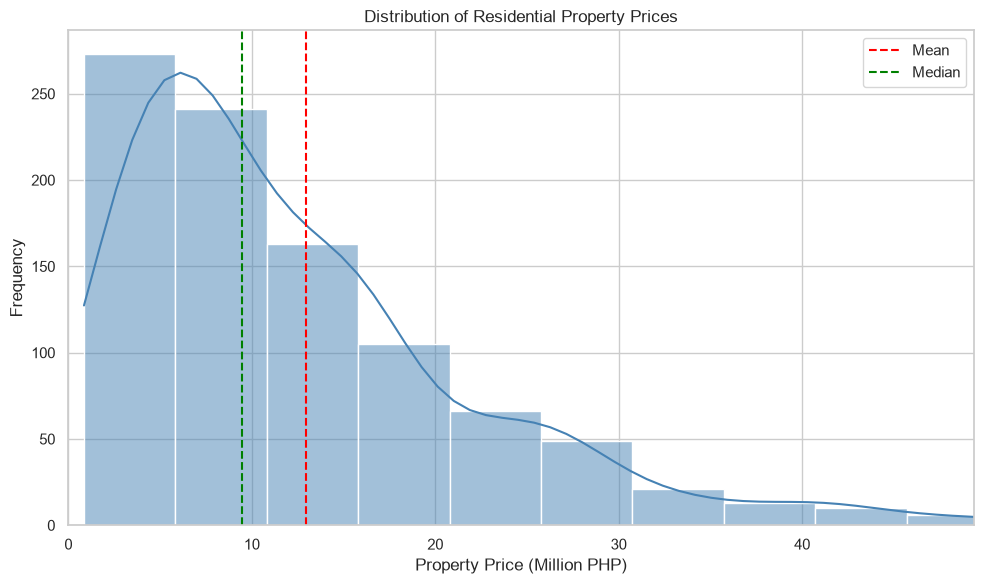

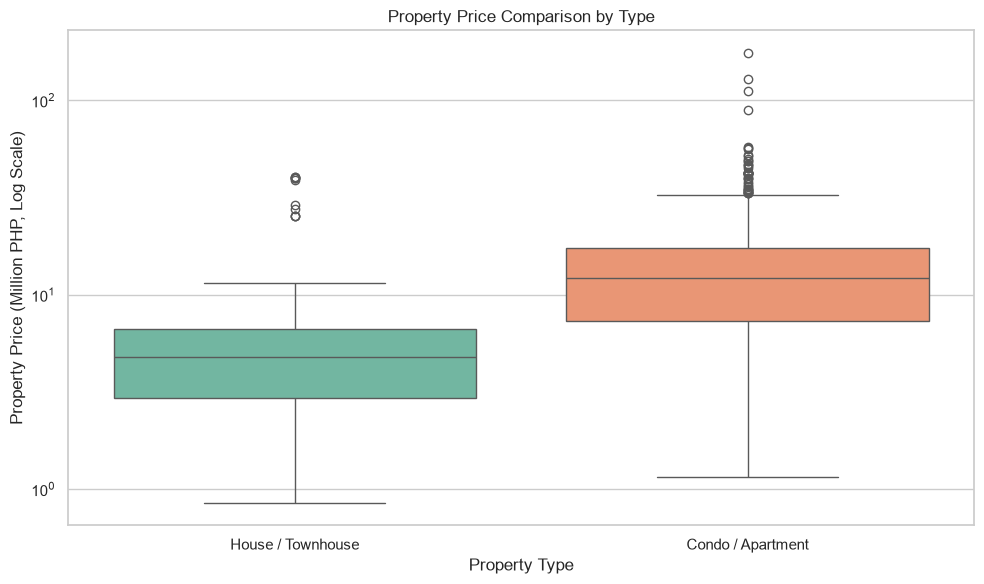

In [11]:
# STEP 15: Property Price Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Prepare data for visualization
viz_df = train_df.copy()

# Convert prices to millions for easier reading
viz_df['Price_Millions'] = (
    viz_df['Price (PHP)'].astype(float) / 1_000_000
)

# GRAPH 1: Property Price Distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=viz_df,
    x='Price_Millions',
    bins=35,
    kde=True,
    color='steelblue'
)

plt.axvline(
    viz_df['Price_Millions'].mean(),
    color='red',
    linestyle='--',
    label='Mean'
)

plt.axvline(
    viz_df['Price_Millions'].median(),
    color='green',
    linestyle='--',
    label='Median'
)

# Zoom to 99th percentile for readability
# No records are removed from the dataset
plt.xlim(
    0,
    viz_df['Price_Millions'].quantile(0.99)
)

plt.title('Distribution of Residential Property Prices')
plt.xlabel('Property Price (Million PHP)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()


# GRAPH 2: Property Price by Property Type
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=viz_df,
    x='Property_Type',
    y='Price_Millions',
    hue='Property_Type',
    palette='Set2',
    legend=False
)

# Log scale helps display extreme property prices
plt.yscale('log')

plt.title('Property Price Comparison by Type')
plt.xlabel('Property Type')
plt.ylabel('Property Price (Million PHP, Log Scale)')
plt.tight_layout()
plt.show()

**Interpretation.** The histogram confirms a long right tail. The box plot (log scale) shows a clear price gap between condos and houses, with several high-end condo outliers, so property type is needed as a model input.

**Trends over time.** Not applicable: the dataset has no listing or sale dates, so we do not plot a time trend.

### Relationships and correlations

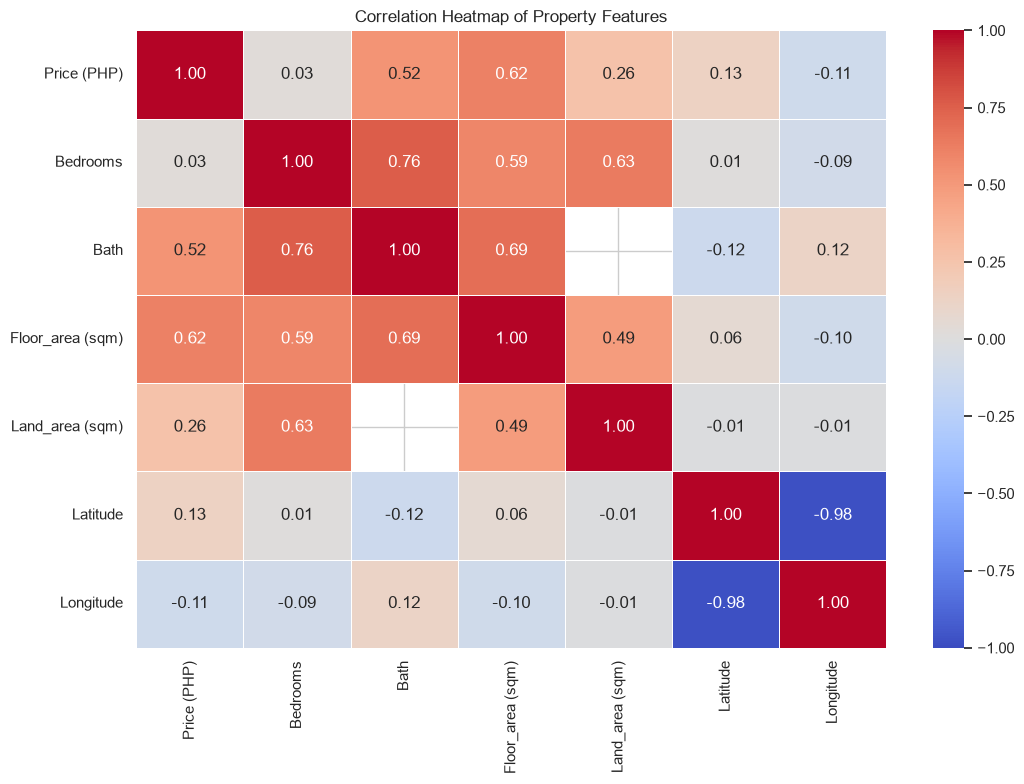

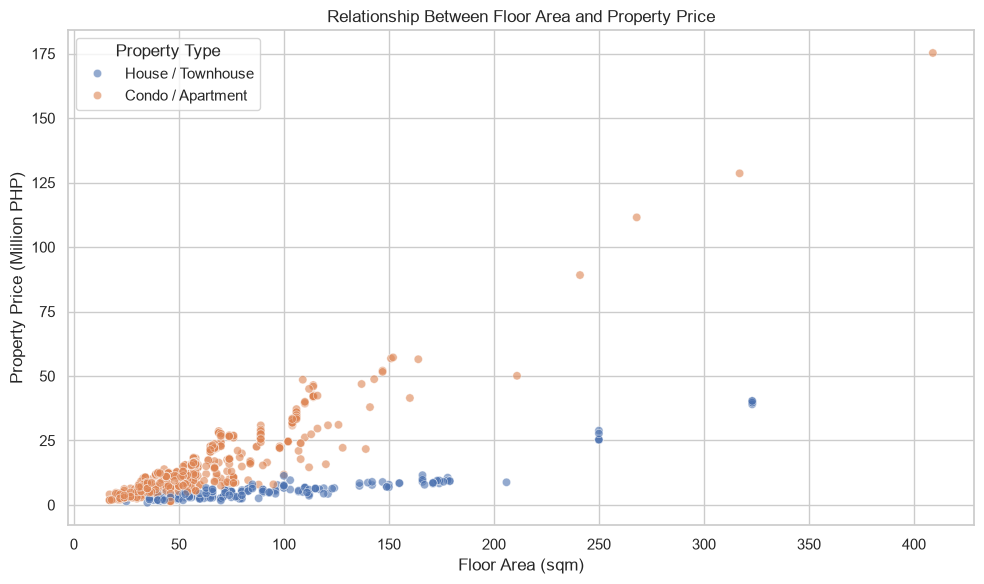

=== CORRELATION WITH PROPERTY PRICE ===


Floor_area (sqm)    0.616
Bath                0.524
Land_area (sqm)     0.264
Latitude            0.133
Bedrooms            0.025
Longitude          -0.106
Name: Price (PHP), dtype: float64

In [12]:
# STEP 16: Correlation and Relationship Analysis

# Select numerical features
correlation_columns = [
    'Price (PHP)',
    'Bedrooms',
    'Bath',
    'Floor_area (sqm)',
    'Land_area (sqm)',
    'Latitude',
    'Longitude'
]

# Calculate correlation matrix
correlation_matrix = train_df[
    correlation_columns
].corr()

# GRAPH 3: Correlation Heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Property Features')
plt.tight_layout()
plt.show()


# GRAPH 4: Floor Area vs Property Price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=viz_df,
    x='Floor_area (sqm)',
    y='Price_Millions',
    hue='Property_Type',
    alpha=0.6
)

plt.title('Relationship Between Floor Area and Property Price')
plt.xlabel('Floor Area (sqm)')
plt.ylabel('Property Price (Million PHP)')
plt.legend(title='Property Type')
plt.tight_layout()
plt.show()


# Display correlations with property price
print("=== CORRELATION WITH PROPERTY PRICE ===")

price_correlations = (
    correlation_matrix['Price (PHP)']
    .drop('Price (PHP)')
    .sort_values(ascending=False)
)

display(price_correlations.round(3))

**Interpretation.** Floor area has the strongest linear relationship with price (r = 0.62), followed by bath (0.52). Bedrooms show almost none (0.03): at the same floor area, more bedrooms means smaller rooms, and large 1-bedroom units tend to be expensive, so bedroom count alone says little. The ratio of floor area to bedrooms captures this, and we add it as a feature below. The scatter plot also shows condos and houses following different price patterns, which again supports including property type.

## Phase 2: Feature Engineering

| Step | What | Why |
|---|---|---|
| Added feature | `Property_Type` | Prices differ strongly by type, and it explains which fields are missing. |
| Added feature | `Log_Floor_Area` | Price grows non-linearly with size. Important for the linear model; tree models are unaffected by monotone transforms. |
| Added feature | `Floor_Area_Per_Bedroom` | Separates spacious units from compact ones with the same bedroom count. |
| Target transform | `log1p(price)` | Reduces skew, makes errors proportional, and guarantees that predictions are positive. |
| Imputation | Median | Robust to outliers. Fitted inside the pipeline on training folds only. |
| Scaling | `StandardScaler` | Puts features on one scale, which the linear model benefits from. |
| Encoding | One-hot | Converts property type to numeric columns. |

`Location` is not used because the web app asks only for property details. The feature function lives in `house_features.py` so that the saved pipeline can be loaded by the Flask app.

In [13]:
import sys
sys.path.insert(0, "..")

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from house_features import create_property_features

base_features = ['Bedrooms', 'Bath', 'Floor_area (sqm)', 'Land_area (sqm)']
model_features = base_features + ['Property_Type']
numeric_model_features = base_features + ['Log_Floor_Area', 'Floor_Area_Per_Bedroom']

X_train_model = X_train[model_features].copy()
X_test_model = X_test[model_features].copy()

preprocessor = Pipeline(steps=[
    ('feature_engineering', FunctionTransformer(create_property_features, validate=False)),
    ('columns', ColumnTransformer(transformers=[
        ('numeric', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), numeric_model_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Property_Type']),
    ])),
])

def with_log_target(regressor):
    """Train on log1p(price) and return predictions in pesos."""
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)

display(create_property_features(X_train_model).head())
print("Model inputs:", model_features)
print("Columns after preprocessing:", preprocessor.fit_transform(X_train_model).shape[1])

,Bedrooms,Bath,Floor_area (sqm),Land_area (sqm),Property_Type,Log_Floor_Area,Floor_Area_Per_Bedroom
823,4.0,NaN,103.0,168.0,House / Townhouse,4.644391,25.75
66,1.0,1.0,56.0,NaN,Condo / Apartment,4.043051,56.00
692,2.0,NaN,89.0,NaN,Condo / Apartment,4.499810,44.50
631,1.0,NaN,58.0,NaN,Condo / Apartment,4.077537,58.00
381,1.0,1.0,NaN,NaN,Condo / Apartment,NaN,NaN


Model inputs: ['Bedrooms', 'Bath', 'Floor_area (sqm)', 'Land_area (sqm)', 'Property_Type']
Columns after preprocessing: 8


## Phase 4: Algorithms

| Algorithm | Type | Why |
|---|---|---|
| Multiple Linear Regression | Linear | An interpretable baseline that shows how much non-linear models add. |
| Random Forest | Ensemble (bagging) | Averages many deep trees, which handles interactions and resists overfitting. |
| XGBoost | Ensemble (boosting) | Builds trees sequentially to correct remaining errors; strong on tabular data. |
| XGBoost (constrained) | Ensemble (boosting) | Same algorithm with monotonic constraints on bedrooms, bath, floor area and land area. This encodes domain knowledge and guards against erratic predictions where data is sparse. |

Each model runs inside a pipeline with preprocessing, so nothing is fitted on the validation folds.

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold, cross_validate
from xgboost import XGBRegressor

# Order follows the preprocessed columns: bedrooms, bath, floor, land, log floor,
# floor per bedroom, then two property-type columns. 1 = non-decreasing, 0 = free.
# Floor area per bedroom stays free: forcing it costs a large amount of accuracy.
MONOTONE_CONSTRAINTS = (1, 1, 1, 1, 1, 0, 0, 0)

algorithms = {
    'Multiple Linear Regression': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(random_state=42, n_jobs=-1),
    'XGBoost Regressor': XGBRegressor(random_state=42, n_jobs=2),
    'XGBoost Regressor (Constrained)': XGBRegressor(
        random_state=42, n_jobs=2, monotone_constraints=MONOTONE_CONSTRAINTS),
}

scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def build_pipeline(regressor):
    return Pipeline(steps=[('preprocessing', clone(preprocessor)), ('model', with_log_target(clone(regressor)))])

baseline_rows = []
for name, regressor in algorithms.items():
    scores = cross_validate(build_pipeline(regressor), X_train_model, y_train, cv=cv, scoring=scoring)
    baseline_rows.append({'Model': name, 'MAE (PHP)': -scores['test_MAE'].mean(),
                          'RMSE (PHP)': -scores['test_RMSE'].mean(), 'R2 Score': scores['test_R2'].mean()})

baseline_df = pd.DataFrame(baseline_rows).sort_values('MAE (PHP)').reset_index(drop=True)
display(baseline_df.round(4))

,Model,MAE (PHP),RMSE (PHP),R2 Score
0,XGBoost Regressor (Constrained),1.552738e+06,3.288154e+06,0.9280
1,XGBoost Regressor,1.617336e+06,3.787946e+06,0.9046
2,Random Forest Regressor,1.670639e+06,3.690957e+06,0.9054
3,Multiple Linear Regression,2.840097e+06,5.426935e+06,0.7864


## Phase 5: Evaluation and Visualization

### Grid search with cross-validation

Each model is tuned with 5-fold `GridSearchCV` over its whole pipeline, using training data only. We choose the model with the lowest cross-validated MAE, because MAE reads directly as "average error in pesos" and is less dominated by a few very expensive units than RMSE.

In [15]:
boosting_grid = {
    'model__regressor__n_estimators': [200, 400],
    'model__regressor__max_depth': [3, 5],
    'model__regressor__learning_rate': [0.03, 0.1],
}
param_grids = {
    'Multiple Linear Regression': {'model__regressor__fit_intercept': [True, False]},
    'Random Forest Regressor': {
        'model__regressor__n_estimators': [100, 200],
        'model__regressor__max_depth': [8, 12, None],
        'model__regressor__min_samples_leaf': [2, 5],
    },
    'XGBoost Regressor': boosting_grid,
    'XGBoost Regressor (Constrained)': boosting_grid,
}

tuned_models = {}
tuning_rows = []
for name, regressor in algorithms.items():
    search = GridSearchCV(build_pipeline(regressor), param_grids[name], scoring=scoring,
                          refit='MAE', cv=cv, n_jobs=1).fit(X_train_model, y_train)
    tuned_models[name] = search.best_estimator_
    i = search.best_index_
    tuning_rows.append({'Model': name, 'MAE (PHP)': -search.cv_results_['mean_test_MAE'][i],
                        'RMSE (PHP)': -search.cv_results_['mean_test_RMSE'][i],
                        'R2 Score': search.cv_results_['mean_test_R2'][i],
                        'Best Parameters': search.best_params_})

tuning_df = pd.DataFrame(tuning_rows).sort_values('MAE (PHP)').reset_index(drop=True)
display(tuning_df)

best_model_name = tuning_df.iloc[0]['Model']
best_pipeline = tuned_models[best_model_name]
print("Selected by cross-validated MAE:", best_model_name)

,Model,MAE (PHP),RMSE (PHP),R2 Score,Best Parameters
0,XGBoost Regressor (Constrained),1.549719e+06,3.223235e+06,0.930317,"{'model__regressor__learning_rate': 0.1, 'mode..."
1,XGBoost Regressor,1.598523e+06,3.201050e+06,0.931356,"{'model__regressor__learning_rate': 0.1, 'mode..."
2,Random Forest Regressor,1.756978e+06,4.034530e+06,0.889189,"{'model__regressor__max_depth': 12, 'model__re..."
3,Multiple Linear Regression,2.840097e+06,5.426935e+06,0.786424,{'model__regressor__fit_intercept': False}


Selected by cross-validated MAE: XGBoost Regressor (Constrained)


### Final evaluation on the untouched test set

The test set was not used for any choice above, so these figures estimate performance on new listings.

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_predictions = {name: model.predict(X_test_model) for name, model in tuned_models.items()}
final_df = pd.DataFrame([
    {'Model': name, 'MAE (PHP)': mean_absolute_error(y_test, pred),
     'RMSE (PHP)': np.sqrt(mean_squared_error(y_test, pred)), 'R2 Score': r2_score(y_test, pred)}
    for name, pred in test_predictions.items()
]).sort_values('MAE (PHP)').reset_index(drop=True)
display(final_df.round(4))

best_pred = np.asarray(test_predictions[best_model_name], dtype=float)
y_actual = np.asarray(y_test, dtype=float)
print("Lowest predicted test price: PHP {:,.0f}".format(best_pred.min()))

by_type = pd.DataFrame({'Type': X_test_model['Property_Type'].values, 'Actual': y_actual, 'Predicted': best_pred})
by_type['Absolute Error'] = (by_type['Actual'] - by_type['Predicted']).abs()
display(by_type.groupby('Type').agg(Listings=('Actual', 'size'), MAE=('Absolute Error', 'mean'),
                                    Median_Error=('Absolute Error', 'median')).round(0))

,Model,MAE (PHP),RMSE (PHP),R2 Score
0,XGBoost Regressor,1.446345e+06,2.283901e+06,0.9531
1,XGBoost Regressor (Constrained),1.470855e+06,2.360372e+06,0.9499
2,Random Forest Regressor,1.716364e+06,3.055534e+06,0.9160
3,Multiple Linear Regression,2.888199e+06,4.512945e+06,0.8168


Lowest predicted test price: PHP 1,883,593


,Listings,MAE,Median_Error
Type,,,
Condo / Apartment,185,1626371.0,931900.0
House / Townhouse,55,947755.0,582422.0


### Performance visualizations

Confusion matrices and decision boundaries apply to classification. For regression, the equivalents are an error comparison, actual-versus-predicted and residual plots, and feature importance.

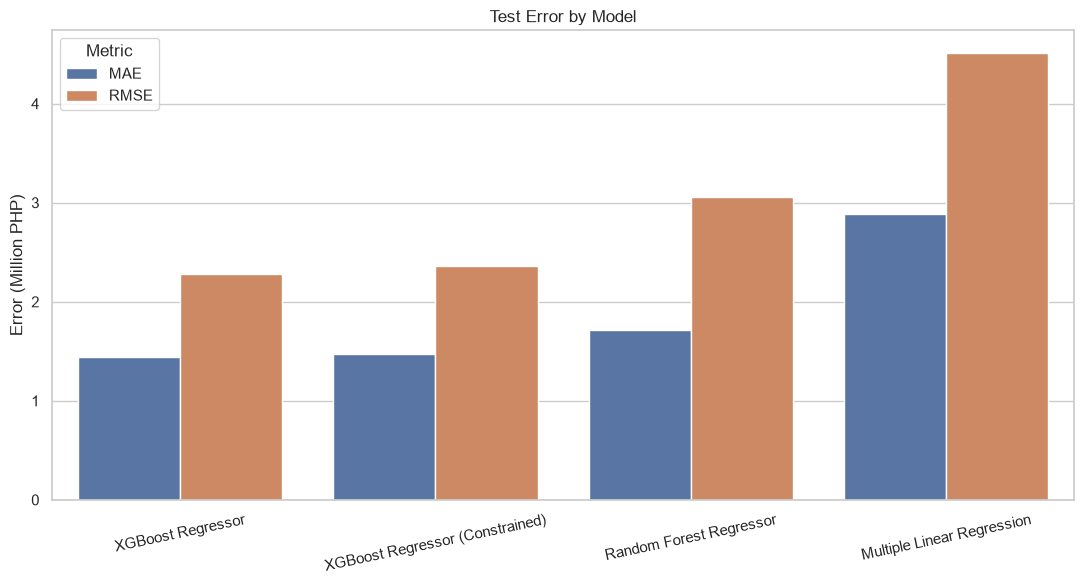

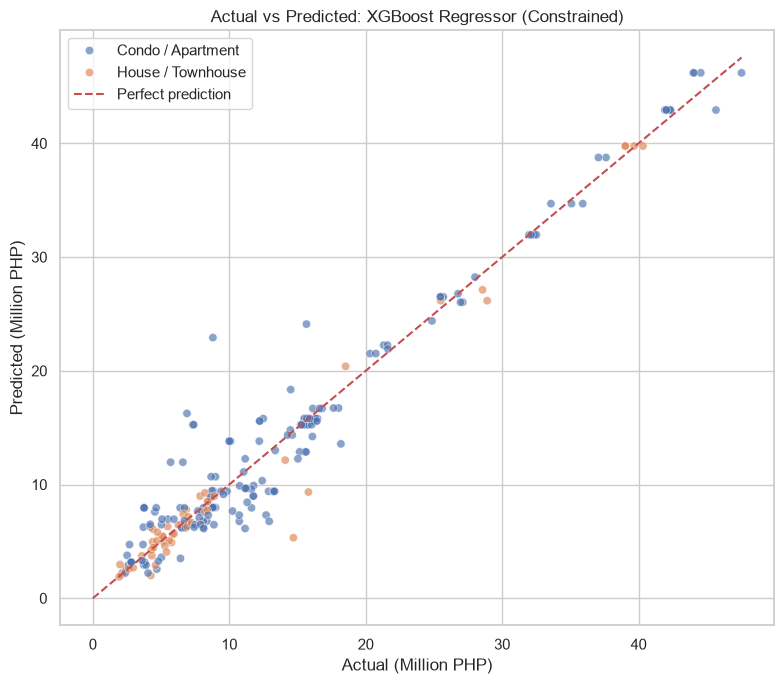

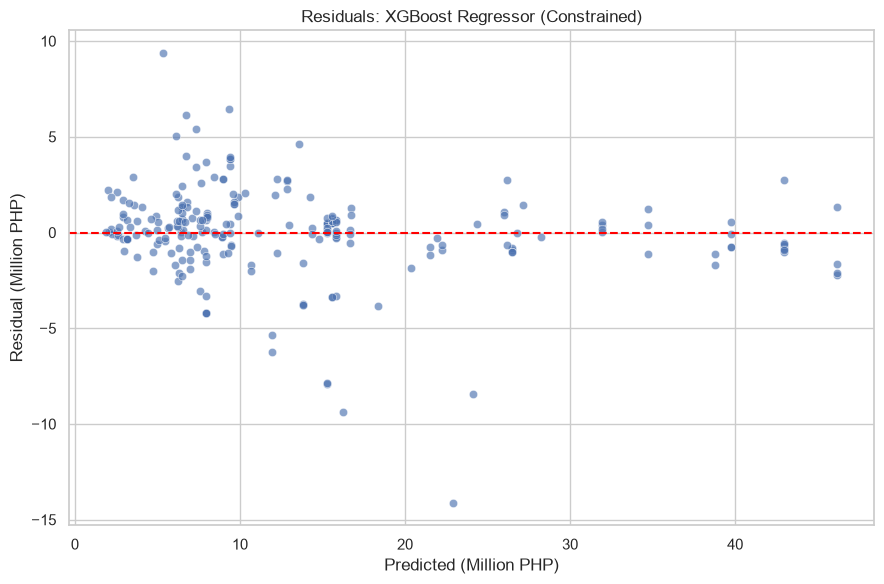

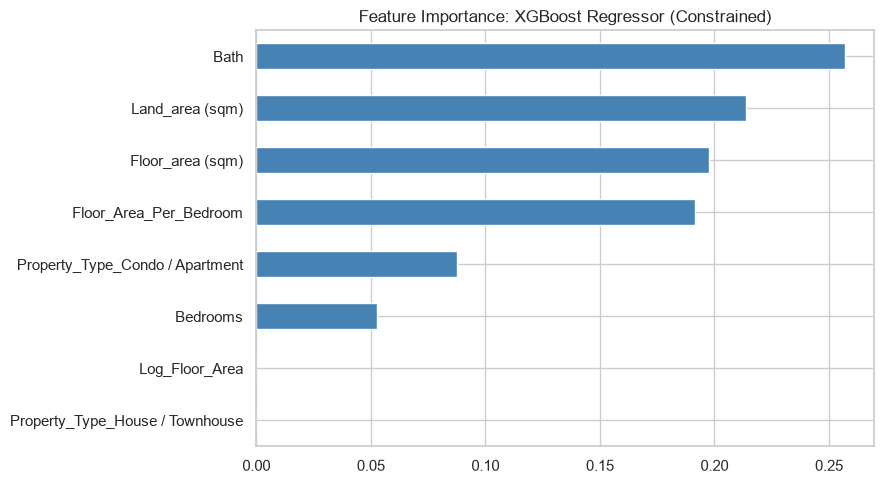

In [17]:
sns.set_theme(style="whitegrid")

plot_data = final_df.assign(MAE=final_df['MAE (PHP)'] / 1e6, RMSE=final_df['RMSE (PHP)'] / 1e6).melt(
    id_vars='Model', value_vars=['MAE', 'RMSE'], var_name='Metric', value_name='Error (Million PHP)')
plt.figure(figsize=(11, 6))
sns.barplot(data=plot_data, x='Model', y='Error (Million PHP)', hue='Metric')
plt.title('Test Error by Model'); plt.xlabel(''); plt.xticks(rotation=12); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 7))
sns.scatterplot(x=y_actual / 1e6, y=best_pred / 1e6, hue=X_test_model['Property_Type'].values, alpha=0.65)
limit = max(y_actual.max(), best_pred.max()) / 1e6
plt.plot([0, limit], [0, limit], 'r--', label='Perfect prediction')
plt.title(f'Actual vs Predicted: {best_model_name}'); plt.xlabel('Actual (Million PHP)'); plt.ylabel('Predicted (Million PHP)')
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 6))
sns.scatterplot(x=best_pred / 1e6, y=(y_actual - best_pred) / 1e6, alpha=0.65)
plt.axhline(0, color='red', linestyle='--')
plt.title(f'Residuals: {best_model_name}'); plt.xlabel('Predicted (Million PHP)'); plt.ylabel('Residual (Million PHP)')
plt.tight_layout(); plt.show()

feature_names = numeric_model_features + list(
    best_pipeline.named_steps['preprocessing'].named_steps['columns']
    .named_transformers_['categorical'].get_feature_names_out(['Property_Type']))
importances = pd.Series(best_pipeline.named_steps['model'].regressor_.feature_importances_, index=feature_names).sort_values()
plt.figure(figsize=(9, 5))
importances.plot.barh(color='steelblue')
plt.title(f'Feature Importance: {best_model_name}'); plt.tight_layout(); plt.show()

## Results and Model Comparison

| Model | CV MAE (₱) | CV R² | Test MAE (₱) | Test RMSE (₱) | Test R² |
|---|---|---|---|---|---|
| XGBoost (constrained) | 1,549,719 | 0.930 | 1,470,855 | 2,360,372 | 0.950 |
| XGBoost | 1,598,523 | 0.931 | 1,446,345 | 2,283,901 | 0.953 |
| Random Forest | 1,756,978 | 0.889 | 1,716,364 | 3,055,534 | 0.916 |
| Multiple Linear Regression | 2,840,097 | 0.786 | 2,888,199 | 4,512,945 | 0.817 |

**Selected model: constrained XGBoost**, which had the lowest cross-validated MAE. Unconstrained XGBoost did slightly better on the test set, but we keep the choice made by cross-validation: picking a winner from test scores would make those scores an unfair estimate. The gap is small (about ₱24,000 in MAE), and the constrained model has the more sensible behaviour.

**Comparison.** Boosting beats bagging here by about ₱250,000 in test MAE, and both ensembles are far ahead of linear regression, which confirms that the price relationship is non-linear and depends on interactions, such as size and property type. Cross-validated and test scores are close for the selected model, so it is not obviously overfitting.

**Reading the plots.** Points follow the perfect-prediction line across the range. The largest misses are between about ₱5M and ₱25M, where homes of similar size can differ a lot in price, which fits the model having no location input. Expensive units sit close to the line, but many listings are units from the same few projects, and some projects appear in both the training and test sets, so scores may be somewhat optimistic for a brand-new development. Average error is about ₱1.63M for condos and ₱0.95M for houses.

**Limitations.**
- Bedroom count is not guaranteed to raise the price, since a given floor area split into more bedrooms means smaller rooms. Forcing that constraint roughly doubled cross-validated error (MAE of about ₱2.85M), so we did not apply it.
- Houses in this dataset almost never list baths, so bath count only affects condo estimates. Land area only affects house estimates.
- The model does not use location, a major real-world price factor, and it is trained on asking prices rather than sale prices.


## Phase 6: Exporting for the Web Application

The export includes everything the Flask app needs:

- **Input limits** per property type, taken from the training data, so the app never asks the model about homes outside what it has seen. Baths are capped at 3 because only three listings have 4, all of them penthouses over ₱100M.
- **Estimated range** from out-of-fold residuals: the 10th to 90th percentile of actual price divided by predicted price, so about 80% of listings should fall inside.
- **Market baseline**: the 25th to 75th percentile of listed prices per property type.
- **Listings** used to show real, similar homes next to an estimate.
- **All four tuned models**, so the app can optionally show each model's estimate side by side.

In [18]:
import json, os
import joblib, sklearn, xgboost
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(clone(best_pipeline), X_train_model, y_train, cv=cv)
ratios = np.asarray(y_train, dtype=float) / oof
low_ratio, high_ratio = np.percentile(ratios, [10, 90])
coverage = np.mean((y_actual >= best_pred * low_ratio) & (y_actual <= best_pred * high_ratio))
print(f"Range: {low_ratio:.3f}x to {high_ratio:.3f}x of the estimate; test coverage {coverage:.1%}")

train_frame = X_train_model.assign(Price=y_train)
limits, baseline = {}, {}
for ptype, group in train_frame.groupby('Property_Type'):
    limits[ptype] = {'Bedrooms': [1, int(group['Bedrooms'].max())],
                     'Floor_area (sqm)': [int(group['Floor_area (sqm)'].min()), int(group['Floor_area (sqm)'].max())]}
    baseline[ptype] = [float(group['Price'].quantile(.25)), float(group['Price'].quantile(.75))]
limits['Condo / Apartment']['Bath'] = [1, 3]
house = train_frame[train_frame['Property_Type'] == 'House / Townhouse']
limits['House / Townhouse']['Land_area (sqm)'] = [int(house['Land_area (sqm)'].min()), int(house['Land_area (sqm)'].max())]

best_row = final_df[final_df['Model'] == best_model_name].iloc[0]
model_info = {
    'model_name': best_model_name, 'target': 'Price (PHP)', 'features': model_features,
    'test_metrics': {'mae': float(best_row['MAE (PHP)']), 'rmse': float(best_row['RMSE (PHP)']), 'r2': float(best_row['R2 Score'])},
    'range_ratio': [float(low_ratio), float(high_ratio)], 'range_test_coverage': float(coverage),
    'limits': limits, 'market_baseline': baseline,
    'scikit_learn_version': sklearn.__version__, 'xgboost_version': xgboost.__version__,
}
listings = residential_df.drop_duplicates('Description')[
    ['Description', 'Location', 'Price (PHP)', 'Bedrooms', 'Bath', 'Floor_area (sqm)', 'Land_area (sqm)', 'Property_Type', 'Link']]

joblib.dump(best_pipeline, '../models/house_price_xgboost.pkl')
joblib.dump(tuned_models, '../models/all_models.pkl')
with open('../models/model_info.json', 'w') as f:
    json.dump(model_info, f, indent=4)
listings.to_json('../models/listings.json', orient='records', indent=0)

os.makedirs('../results', exist_ok=True)
baseline_df.to_csv('../results/baseline_model_comparison.csv', index=False)
tuning_df.to_csv('../results/tuned_model_comparison.csv', index=False)
final_df.to_csv('../results/final_model_comparison.csv', index=False)

loaded = joblib.load('../models/house_price_xgboost.pkl')
print("Reloaded model matches:", np.allclose(loaded.predict(X_test_model), best_pred))
print(json.dumps({k: model_info[k] for k in ('limits', 'market_baseline', 'range_ratio', 'test_metrics')}, indent=1))
print(len(listings), "listings exported")

Range: 0.749x to 1.262x of the estimate; test coverage 77.9%
Reloaded model matches: True
{
 "limits": {
  "Condo / Apartment": {
   "Bedrooms": [
    1,
    4
   ],
   "Floor_area (sqm)": [
    17,
    409
   ],
   "Bath": [
    1,
    3
   ]
  },
  "House / Townhouse": {
   "Bedrooms": [
    1,
    5
   ],
   "Floor_area (sqm)": [
    25,
    323
   ],
   "Land_area (sqm)": [
    36,
    251
   ]
  }
 },
 "market_baseline": {
  "Condo / Apartment": [
   7288260.0,
   17363800.0
  ],
  "House / Townhouse": [
   2930800.0,
   6650000.0
  ]
 },
 "range_ratio": [
  0.748824383412674,
  1.2616594282682532
 ],
 "test_metrics": {
  "mae": 1470854.6067708333,
  "rmse": 2360372.407119715,
  "r2": 0.9498789895078149
 }
}
1125 listings exported
